In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [19]:
df = pd.read_csv(r"C:\Users\Siddhi\Downloads\sales_data_sample.csv", encoding='latin1')

In [20]:
df = df.select_dtypes(include=['number'])
df = df.dropna()

In [21]:
scaler = StandardScaler()
X = scaler.fit_transform(df)

In [22]:
wcss = []

In [23]:
# Tests 1 to 10 clusters and stores WCSS values.
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

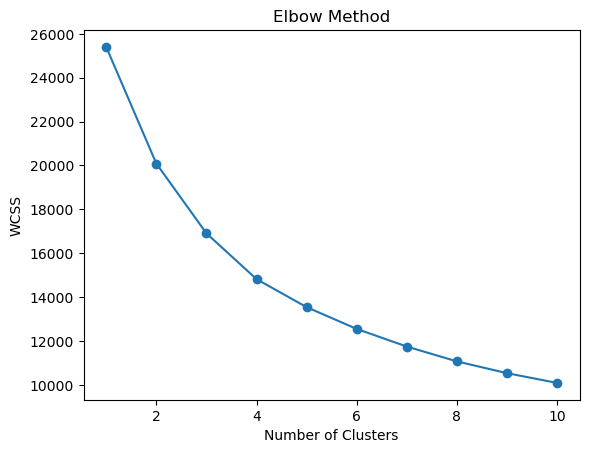

In [32]:
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method') # The Elbow Method is used to find the optimal number of clusters (k) in K-Means
plt.show()

In [25]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)

In [26]:
df['Cluster'] = clusters

In [27]:
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP,Cluster
0,10107,30,95.70,2,2871.00,1,2,2003,95,1
1,10121,34,81.35,5,2765.90,2,5,2003,95,2
2,10134,41,94.74,2,3884.34,3,7,2003,95,1
3,10145,45,83.26,6,3746.70,3,8,2003,95,1
4,10159,49,100.00,14,5205.27,4,10,2003,95,1


In [28]:
print("Cluster Centers:\n", kmeans.cluster_centers_)

Cluster Centers:
 [[ 0.80575256  0.15427129  0.15853912 -0.09904797  0.13718852 -1.15312495
  -1.15590439  1.18162177  0.07017959]
 [-0.26380266  0.03950733  0.70579807  0.01510919  0.53506418  0.50914456
   0.50626827 -0.44498338  0.62400764]
 [-0.30832653 -0.17656987 -1.05002961  0.0605155  -0.80979834  0.26939922
   0.2754067  -0.37626384 -0.87164775]]


In [29]:
# WCSS = Within-Cluster Sum of Squares
# K-Means = Groups similar data points into clusters
# Elbow Method = Helps identify the optimal number of clusters
# Centroid = Center point of a cluster